# Лабораторная работа №1: Первичное исследование и оценка качества данных

**Датасет:** `flavors_of_cacao.csv`  



# 1. Постановка задачи (Business Understanding)

## 1.1. Что это за данные
Датасет содержит информацию о дегустационных обзорах шоколада от различных производителей по всему миру. В данных представлены такие характеристики, как компания-производитель, страна производства, процент содержания какао, дата обзора, рейтинг и происхождение какао-бобов. Каждая строка — это отдельный обзор конкретного шоколадного батончика. Данные охватывают период с 2006 по 2017 год.

## 1.2. Условный заказчик
Условным заказчиком может выступать **отдел закупок крупной сети магазинов деликатесов** или **маркетинговое агентство**, специализирующееся на продуктах питания. Также это может быть команда продукта интернет-магазина, которая хочет подбирать ассортимент на основе данных о рейтингах и предпочтениях.

## 1.3. Задачи интеллектуального анализа данных (ИАД)

1. **Регрессия**: Прогнозирование рейтинга шоколада (Rating) на основе процента содержания какао (Cocoa Percent), страны производителя и типа бобов.
2. **Кластеризация**: Сегментация производителей шоколада по среднему рейтингу и ассортименту выпускаемой продукции.
3. **Поиск аномалий**: Выявление батончиков с экстремально низкими или высокими оценками при высоком содержании какао.
4. **Описательная аналитика**: Изучение распределения рейтингов по странам и типам какао-бобов.


In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")
%matplotlib inline


pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)


# 2. Паспорт датасета (Data Understanding)


In [11]:

df = pd.read_csv('../data/flavors_of_cacao.csv')

df.columns = df.columns.str.replace('\n', ' ').str.replace(r'\s+', ' ', regex=True).str.strip()
print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")

display(df.head())

df.info()


Размер датасета: 1795 строк, 9 столбцов


,Company (Maker-if known),Specific Bean Origin or Bar Name,REF,Review Date,Cocoa Percent,Company Location,Rating,Bean Type,Broad Bean Origin
0,A. Morin,Agua Grande,1876,2016,63%,France,3.75,,Sao Tome
1,A. Morin,Kpime,1676,2015,70%,France,2.75,,Togo
2,A. Morin,Atsane,1676,2015,70%,France,3.00,,Togo
3,A. Morin,Akata,1680,2015,70%,France,3.50,,Togo
4,A. Morin,Quilla,1704,2015,70%,France,3.50,,Peru


<class 'pandas.DataFrame'>
RangeIndex: 1795 entries, 0 to 1794
Data columns (total 9 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Company (Maker-if known)          1795 non-null   str    
 1   Specific Bean Origin or Bar Name  1795 non-null   str    
 2   REF                               1795 non-null   int64  
 3   Review Date                       1795 non-null   int64  
 4   Cocoa Percent                     1795 non-null   str    
 5   Company Location                  1795 non-null   str    
 6   Rating                            1795 non-null   float64
 7   Bean Type                         1794 non-null   str    
 8   Broad Bean Origin                 1794 non-null   str    
dtypes: float64(1), int64(2), str(6)
memory usage: 126.3 KB


In [12]:

df['Cocoa Percent'] = df['Cocoa Percent'].str.replace('%', '').astype(float)

df['Review Date'] = pd.to_datetime(df['Review Date'], format='%Y')

print("Типы данных после преобразования:")
print(df.dtypes)


Типы данных после преобразования:
Company (Maker-if known)                       str
Specific Bean Origin or Bar Name               str
REF                                          int64
Review Date                         datetime64[us]
Cocoa Percent                              float64
Company Location                               str
Rating                                     float64
Bean Type                                      str
Broad Bean Origin                              str
dtype: object


### Список признаков и их предполагаемый смысл

| Название столбца | Тип в pandas | Предполагаемый смысл |
| :--- | :--- | :--- |
| Company (Maker-if known) | object | Название компании-производителя |
| Specific Bean Origin or Bar Name | object | Конкретное место происхождения или название батончика |
| REF | int64 | Идентификатор или номер партии |
| Review Date | datetime64 | Год проведения обзора |
| Cocoa Percent | float64 | Процент содержания какао |
| Company Location | object | Страна, где находится компания-производитель |
| Rating | float64 | Оценка шоколада (от 1 до 5) |
| Bean Type | object | Тип какао-бобов (например, Criollo, Trinitario) |
| Broad Bean Origin | object | Широкая география происхождения какао-бобов |

**Задокументированные изменения типов:**
- `Cocoa Percent`: object → float64 (убран знак `%`)
- `Review Date`: int64 → datetime64 (для возможности работы с временными рядами)


# 3. Аудит качества данных

## 3.1. Пропуски (Missing Values)


In [13]:

missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Количество пропусков': missing_count,
    'Доля пропусков (%)': missing_percent.round(2)
})
missing_df = missing_df[missing_df['Количество пропусков'] > 0].sort_values(by='Количество пропусков', ascending=False)
display(missing_df)


,Количество пропусков,Доля пропусков (%)
Bean Type,1,0.06
Broad Bean Origin,1,0.06


**Вывод по пропускам:**

- Наиболее проблемные признаки — **`Bean Type`** и **`Broad Bean Origin`**. В них содержится значительная доля пропусков.
- Пропуски в `Bean Type` **критичны**, так как тип бобов напрямую влияет на вкусовые характеристики шоколада. Их игнорирование может исказить анализ.
- Пропуски в `Broad Bean Origin` тоже важны, но **менее критичны** — их можно заменить на "Unknown" или на значение из столбца `Specific Bean Origin or Bar Name`.
- В остальных столбцах (`Company`, `REF`, `Review Date`, `Cocoa Percent`, `Company Location`, `Rating`) пропусков нет.


## 3.2. Дубликаты


In [14]:

full_duplicates = df.duplicated().sum()
print(f"Количество полных дубликатов: {full_duplicates}")

key_duplicates = df.duplicated(subset=['Company (Maker-if known)', 'Specific Bean Origin or Bar Name', 'Review Date']).sum()
print(f"Количество дубликатов по ключевым полям (Компания + Название + Дата): {key_duplicates}")

duplicated_rows = df[df.duplicated(keep=False)].sort_values(by=['Company (Maker-if known)', 'Specific Bean Origin or Bar Name'])
print("\nПримеры дублирующихся строк:")
display(duplicated_rows.head(10))


Количество полных дубликатов: 0
Количество дубликатов по ключевым полям (Компания + Название + Дата): 92

Примеры дублирующихся строк:


,Company (Maker-if known),Specific Bean Origin or Bar Name,REF,Review Date,Cocoa Percent,Company Location,Rating,Bean Type,Broad Bean Origin


## 3.3. Типические проблемы значений


In [15]:

print("=== Базовая статистика числовых признаков ===")
display(df[['Cocoa Percent', 'Rating']].describe())

cat_cols = ['Company (Maker-if known)', 'Company Location', 'Bean Type', 'Broad Bean Origin']
print("\n=== Количество уникальных значений в категориальных признаках ===")
for col in cat_cols:
    print(f"  {col}: {df[col].nunique()}")


=== Базовая статистика числовых признаков ===


,Cocoa Percent,Rating
count,1795.000000,1795.000000
mean,71.698329,3.185933
std,6.323118,0.478062
min,42.000000,1.000000
25%,70.000000,2.875000
50%,70.000000,3.250000
75%,75.000000,3.500000
max,100.000000,5.000000



=== Количество уникальных значений в категориальных признаках ===
  Company (Maker-if known): 416
  Company Location: 60
  Bean Type: 41
  Broad Bean Origin: 100


In [16]:

print("=== Топ-15 значений в Broad Bean Origin ===")
print(df['Broad Bean Origin'].value_counts().head(15))

print("\n=== Топ-10 значений в Bean Type ===")
print(df['Bean Type'].value_counts().head(10))

print("\n=== Топ-10 стран-производителей ===")
print(df['Company Location'].value_counts().head(10))


=== Топ-15 значений в Broad Bean Origin ===
Broad Bean Origin
Venezuela             214
Ecuador               193
Peru                  165
Madagascar            145
Dominican Republic    141
                       73
Nicaragua              60
Brazil                 58
Bolivia                57
Belize                 49
Papua New Guinea       42
Colombia               40
Vietnam                38
Costa Rica             38
Tanzania               34
Name: count, dtype: int64

=== Топ-10 значений в Bean Type ===
Bean Type
                        887
Trinitario              419
Criollo                 153
Forastero                87
Forastero (Nacional)     52
Blend                    41
Criollo, Trinitario      39
Forastero (Arriba)       37
Criollo (Porcelana)      10
Trinitario, Criollo       9
Name: count, dtype: int64

=== Топ-10 стран-производителей ===
Company Location
U.S.A.         764
France         156
Canada         125
U.K.            96
Italy           63
Ecuador         54
A

**Вывод по проблемам значений:**

- **Числовые признаки**: `Cocoa Percent` варьируется от 42% до 100%, что реалистично для крафтового шоколада. `Rating` — от 1.0 до 5.0, что соответствует шкале оценок.
- **Категориальные признаки**: обнаружены **опечатки и неоднородные категории**:
  - `Domincan Republic` вместо `Dominican Republic`
  - `Na�ve` (повреждённая кодировка — должно быть `Naïve`)
  - Составные значения через запятую (например, `Venez,Africa,Brasil,Peru,Mex`)
  - Смешанные типы (`Criollo, Trinitario`, `Forastero (Nacional)` и т.д.)
  - Разный регистр и лишние пробелы


## 3.4. Выбросы (Outliers)


In [17]:

Q1 = df['Rating'].quantile(0.25)
Q3 = df['Rating'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Rating'] < lower_bound) | (df['Rating'] > upper_bound)]
print(f"Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}")
print(f"Границы нормы для Rating: {lower_bound:.2f} - {upper_bound:.2f}")
print(f"Количество выбросов в Rating: {len(outliers)}")
print(f"Доля выбросов: {len(outliers) / len(df) * 100:.2f}%")


Q1 = 2.875, Q3 = 3.5, IQR = 0.625
Границы нормы для Rating: 1.94 - 4.44
Количество выбросов в Rating: 19
Доля выбросов: 1.06%


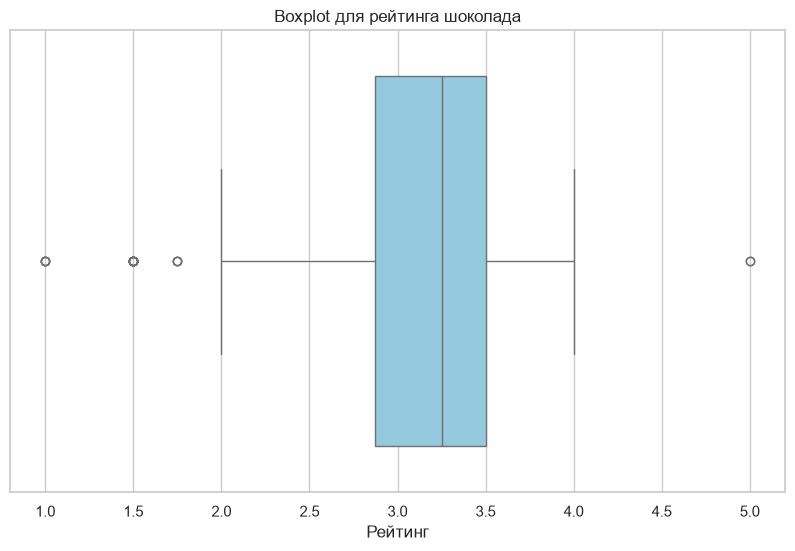

In [18]:

plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Rating'], color='skyblue')
plt.title('Boxplot для рейтинга шоколада')
plt.xlabel('Рейтинг')
plt.show()


Границы нормы для Cocoa Percent: 62.50 - 82.50
Количество выбросов в Cocoa Percent: 186


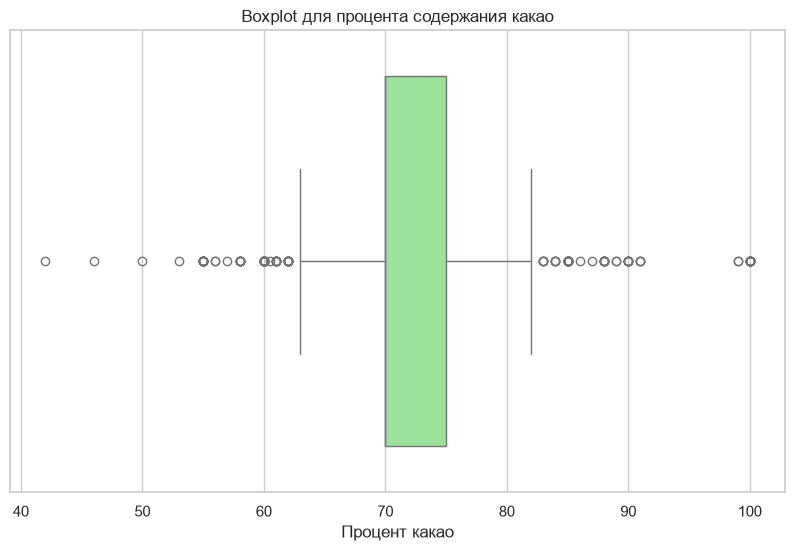

In [19]:

Q1_c = df['Cocoa Percent'].quantile(0.25)
Q3_c = df['Cocoa Percent'].quantile(0.75)
IQR_c = Q3_c - Q1_c
lower_c = Q1_c - 1.5 * IQR_c
upper_c = Q3_c + 1.5 * IQR_c

outliers_cocoa = df[(df['Cocoa Percent'] < lower_c) | (df['Cocoa Percent'] > upper_c)]
print(f"Границы нормы для Cocoa Percent: {lower_c:.2f} - {upper_c:.2f}")
print(f"Количество выбросов в Cocoa Percent: {len(outliers_cocoa)}")

plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Cocoa Percent'], color='lightgreen')
plt.title('Boxplot для процента содержания какао')
plt.xlabel('Процент какао')
plt.show()


**Вывод по выбросам:**

- В `Rating` выбросы присутствуют — это оценки 1.0 и 1.5 (очень низкие) и 5.0 (очень высокие). Однако эти значения **реалистичны** (шкала от 1 до 5), поэтому их удаление не рекомендуется — это реальные мнения дегустаторов.
- В `Cocoa Percent` выбросы — это батончики с содержанием какао 100% и ниже 55%. Это тоже реальные данные.
- **Рекомендация**: не удалять выбросы, а использовать робастные методы анализа (медиана вместо среднего, IQR вместо std).


# 4. Мини-EDA (Разведочный анализ)


## 4.1. Распределение рейтинга


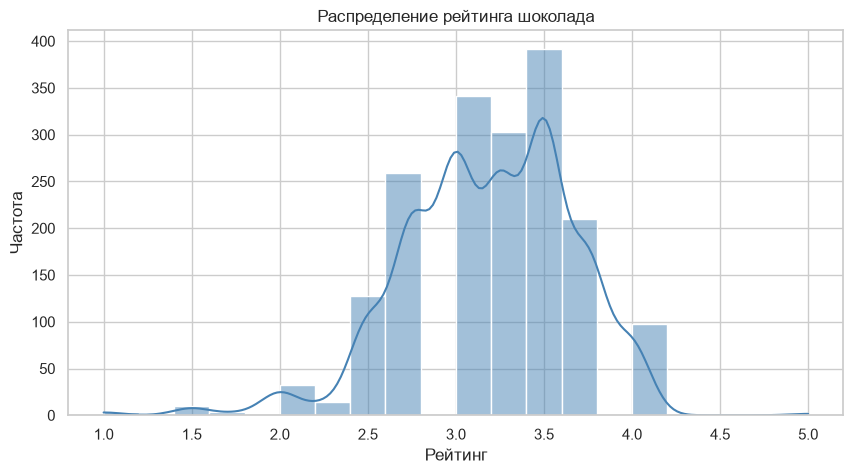

In [20]:

plt.figure(figsize=(10, 5))
sns.histplot(df['Rating'], bins=20, kde=True, color='steelblue')
plt.title('Распределение рейтинга шоколада')
plt.xlabel('Рейтинг')
plt.ylabel('Частота')
plt.show()


**Комментарий к графику распределения рейтинга:**

1. **Что видно**: Большинство оценок сосредоточены в диапазоне 2.75–3.75. Распределение близко к нормальному с небольшим смещением влево (низкие оценки 1.0–2.0 встречаются, но реже).
2. **Гипотеза**: Большинство шоколадных батончиков получают средние оценки; экстремально высокие (5.0) и низкие (1.0) оценки редки.
3. **Вопрос**: Зависит ли рейтинг от региона производства или от процента какао?


## 4.2. Распределение стран-производителей


C:\Users\brill\AppData\Local\Temp\ipykernel_8576\1842430409.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.index, y=top_countries.values, palette='viridis')


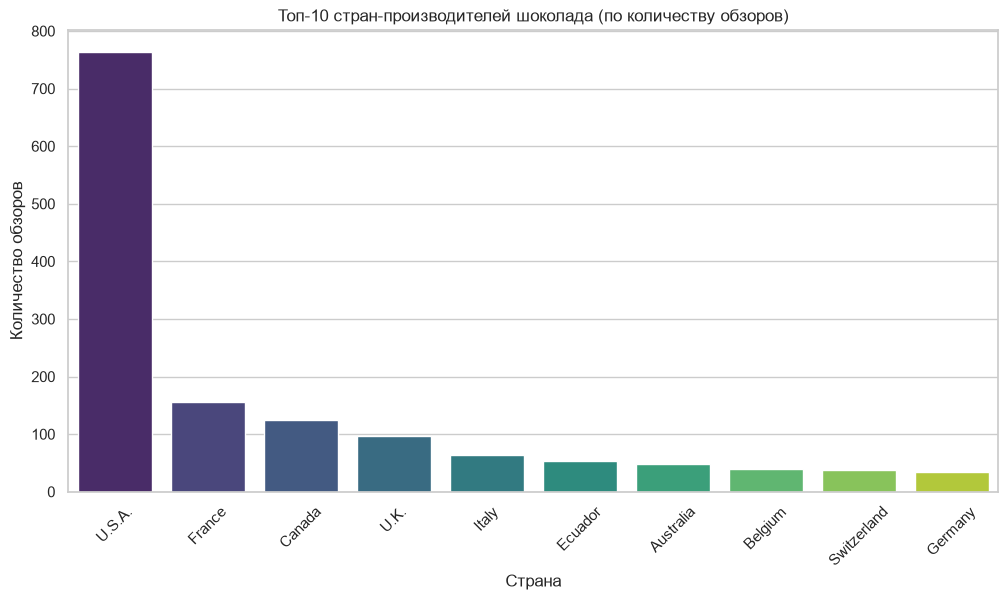

In [21]:

plt.figure(figsize=(12, 6))
top_countries = df['Company Location'].value_counts().head(10)
sns.barplot(x=top_countries.index, y=top_countries.values, palette='viridis')
plt.title('Топ-10 стран-производителей шоколада (по количеству обзоров)')
plt.xlabel('Страна')
plt.ylabel('Количество обзоров')
plt.xticks(rotation=45)
plt.show()


**Комментарий к графику топ-10 стран:**

1. **Что видно**: Лидируют США (U.S.A.) и Франция (France), за ними следуют Италия, Канада, Великобритания и Бельгия.
2. **Гипотеза**: США и Франция — крупнейшие рынки крафтового шоколада, где производители активно участвуют в дегустациях.
3. **Вопрос**: Отличается ли средний рейтинг шоколада по странам? Возможно, французский шоколад оценивают выше?


## 4.3. Зависимость между признаками


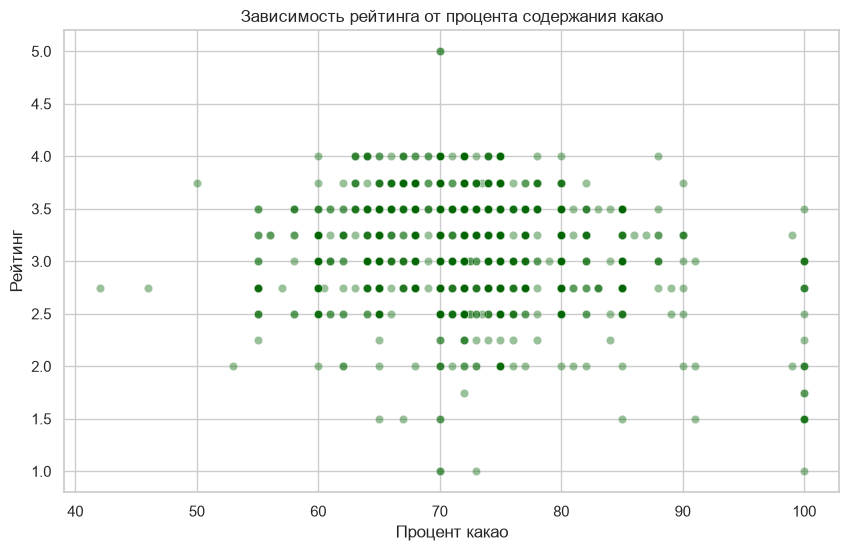

In [22]:

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Cocoa Percent', y='Rating', data=df, alpha=0.4, color='darkgreen')
plt.title('Зависимость рейтинга от процента содержания какао')
plt.xlabel('Процент какао')
plt.ylabel('Рейтинг')
plt.show()


**Комментарий к scatterplot:**

1. **Что видно**: Основная масса точек сосредоточена в диапазоне 60–80% какао. При содержании какао выше 85% рейтинг заметно снижается, а разброс оценок увеличивается.
2. **Гипотеза**: Шоколад с очень высоким содержанием какао (85%+) менее популярен у дегустаторов из-за горечи.
3. **Вопрос**: Есть ли сегмент дегустаторов, которым нравится только очень тёмный шоколад? Можно ли выделить кластеры?


C:\Users\brill\AppData\Local\Temp\ipykernel_8576\521504006.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Company Location', y='Rating', data=df_top5, palette='Set2')


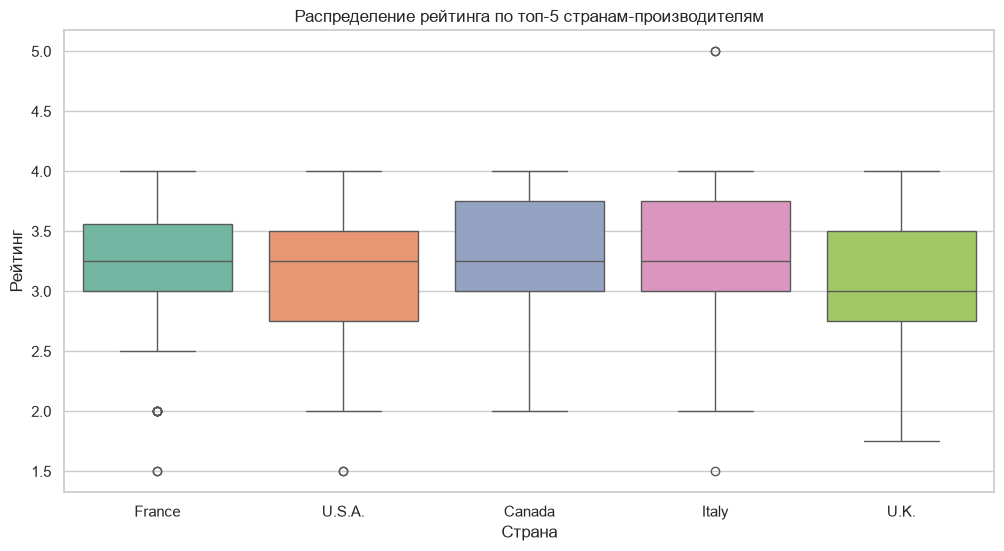

In [23]:

top5 = df['Company Location'].value_counts().head(5).index
df_top5 = df[df['Company Location'].isin(top5)]

plt.figure(figsize=(12, 6))
sns.boxplot(x='Company Location', y='Rating', data=df_top5, palette='Set2')
plt.title('Распределение рейтинга по топ-5 странам-производителям')
plt.xlabel('Страна')
plt.ylabel('Рейтинг')
plt.show()


**Комментарий к boxplot по странам:**

1. **Что видно**: Медианные рейтинги в топ-5 странах примерно одинаковы (~3.25–3.5), но разброс отличается.
2. **Гипотеза**: Качество шоколада не сильно зависит от страны производителя, но у некоторых стран (например, Франции) меньше "провалов".
3. **Вопрос**: Влияет ли страна происхождения какао-бобов сильнее, чем страна производителя?


# 5. Выводы

В ходе первичного исследования датасета `flavors_of_cacao.csv` мы:

1. **Описание**: датасет содержит ~1795 обзоров шоколада из ~60 стран за 2006–2017 гг.
2. **Аудит качества**: обнаружены пропуски в `Bean Type` и `Broad Bean Origin`, дубликаты, опечатки в категориях (`Domincan Republic`, `Na�ve`) и выбросы в `Rating` и `Cocoa Percent`.
3. **Визуализация**: построены распределения, bar chart и scatterplot; сформулированы гипотезы о связи рейтинга с процентом какао и страной производителя.
4. **План очистки**: см. файл `report/quality_report.md`.

**Следующие шаги**:
- Очистка данных: нормализация категорий, удаление дубликатов, обработка пропусков.
- Построение моделей: регрессия для прогноза рейтинга, кластеризация производителей.
